# Max-Cut

A college holds its exam day in two sittings, morning and afternoon. Many students take several
exams, and two exams in the same sitting are a problem for anyone sitting both: one has to be moved
to a make-up day. For each pair of exams the college knows how many students take both. The
question is **which exams go in which sitting, so that as many of those students as possible have
their two exams apart**.

Draw each exam as a vertex and each shared group of students as a weighted edge. Splitting the
vertices into two sides and counting the weight of the edges that cross is a Max-Cut problem. The
same model describes dividing a network, separating rivals into two teams, and arranging wires
between the two sides of a circuit board.

In this notebook you will:

1. describe the exams as a weighted graph,
2. solve it and draw the graph with the cut edges emphasized,
3. check the result yourself, and prove it by trying every split,
4. drop a rule and see the two sittings go lopsided,
5. change the size of the exam hall and see what each seat limit costs,
6. restart from an existing plan with an exam pinned.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.ticker import MaxNLocator

from optimaru import max_cut as mc
from optimaru.max_cut import constraints as rules
from optimaru.max_cut.models import EdgeModel, MaxCutProblemModel, VertexPairModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the exams

One pydantic model holds the graph and the rules, and `partition` is what the solver fills in.

| Object | What it holds |
| --- | --- |
| `EdgeModel` | `source`, `target` and a non-negative integer `weight`: here, the students taking both |
| `VertexPairModel` | two vertices, `first` and `second` |
| `MaxCutProblemModel` | `vertices`, `edges`, `min_partition_size`, `max_partition_size`, `fixed_partition`, `same_partition_pairs`, `different_partition_pairs` |

The two sides are numbered 0 and 1. `max_partition_size` and `min_partition_size` apply to both
sides. A split and its mirror image are the same plan, so which side is called morning is arbitrary.

Here is a fictional exam day with 22 exams. Five core subjects are taken by most students, so they
share students with most other exams. The exam hall takes at most 13 papers per sitting. Biology and
Chemistry use the same lab benches, so they go together. Optics and Mechanics have one examiner, who
cannot be in both rooms, so they go apart.

In [2]:
CORE = ["Calculus", "Physics", "Programming", "Statistics", "Writing"]
ELECTIVES = [
    "Algebra", "Mechanics", "Optics", "Databases", "Networks", "Compilers", "Ethics", "Economics", "Biology",
    "Chemistry", "Geology", "Astronomy", "Graphics", "Robotics", "Logic", "History", "Design",
]
EXAMS = ELECTIVES + CORE
HALL_LIMIT = 13

rng = np.random.default_rng(6)
shared = {}
for core in CORE:
    for elective in rng.choice(ELECTIVES, 11, replace=False):
        shared[core, str(elective)] = int(rng.integers(6, 22))
for _ in range(14):
    first, second = rng.choice(len(ELECTIVES), 2, replace=False)
    shared.setdefault((ELECTIVES[first], ELECTIVES[second]), int(rng.integers(2, 10)))
for first, second in [(0, 1), (0, 3), (2, 3), (1, 4)]:
    shared[CORE[first], CORE[second]] = int(rng.integers(3, 9))


def make_problem(limit=HALL_LIMIT, **fields):
    """A fresh, unsolved exam day. The solver works in place, so each experiment gets its own."""
    return MaxCutProblemModel(
        vertices=EXAMS,
        edges=[EdgeModel(source=a, target=b, weight=students) for (a, b), students in shared.items()],
        min_partition_size=len(EXAMS) - limit,
        max_partition_size=limit,
        same_partition_pairs=[VertexPairModel(first="Biology", second="Chemistry")],
        different_partition_pairs=[VertexPairModel(first="Optics", second="Mechanics")],
        **fields,
    )


total_students = sum(shared.values())
print(f"{len(EXAMS)} exams, {len(shared)} pairs with shared students, {total_students} shared places in total")

22 exams, 72 pairs with shared students, 840 shared places in total


`min_partition_size` is set to the same effect as the hall limit: if neither sitting may exceed 13
of 22 exams, neither can have fewer than 9. Stating it matters at the extreme, as section 5 explains.

Each exam sits on a circle below, core subjects in dark. A thicker edge means more students in common.

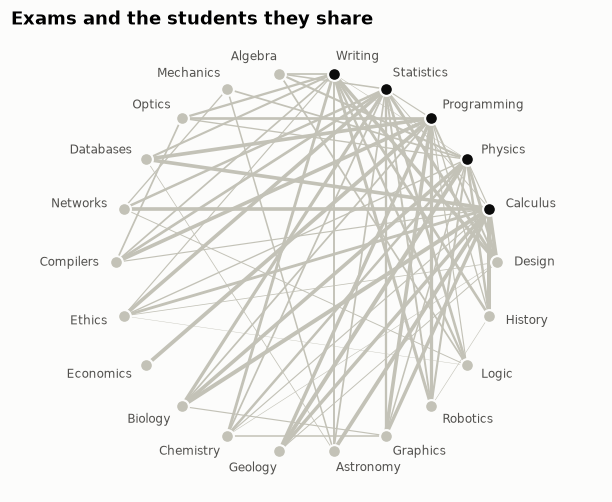

In [3]:
angles = np.linspace(0, 2 * np.pi, len(EXAMS), endpoint=False) + np.pi / 2 + np.pi / len(EXAMS)
CIRCLE = {exam: (np.cos(angle), np.sin(angle)) for exam, angle in zip(EXAMS, angles)}


def draw_labels(ax):
    for exam, (x, y) in CIRCLE.items():
        ax.text(1.09 * x, 1.09 * y, exam, fontsize=8, color=INK, va="center", ha="left" if x >= 0 else "right")
    ax.set(xlim=(-1.55, 1.55), ylim=(-1.2, 1.2), aspect="equal")
    ax.axis("off")


fig, ax = plt.subplots(figsize=(7, 5.4))
for (a, b), students in shared.items():
    ax.plot(*zip(CIRCLE[a], CIRCLE[b]), color="#c3c2b7", linewidth=students / 8, zorder=1)
for exam, (x, y) in CIRCLE.items():
    ax.scatter(x, y, s=70, color="#0b0b0b" if exam in CORE else "#c3c2b7", edgecolor="#fcfcfb", linewidth=1.4,
               zorder=2)
draw_labels(ax)
ax.set_title("Exams and the students they share")
plt.show()

## 2. Solve it

`mc.solve` fills in `partition`, a dict from vertex to side, plus `cut_weight`, `score_hard` and
`score_soft`, and returns the score. This use case has no compiled core: it runs a simulated
annealing written in Python, starting from alternating sides. Each step moves one vertex to the other
side, or swaps two vertices when `min_partition_size` equals `max_partition_size`. The search stops at
`time_limit_seconds` or after `SolverConfig.max_iterations` steps, 50,000 by default, whichever comes
first.

The score has two levels, compared in order:

- **hard**: minus the broken fixed sides and pair rules and the vertices beyond the size limits,
  where `0` means the plan is allowed
- **soft**: the total weight of the cut edges. Here higher is better and the level is positive.

An exam here shares tens of students with others, so a step can lose tens of points. `temperature=30`
replaces the default of 2.0 so that the search can accept such a step early in a run.

In [4]:
def search_settings(seed=42):
    return mc.SolverConfig(temperature=30, random_seed=seed)


problem = make_problem()
score = mc.solve(problem, time_limit_seconds=5, config=search_settings())

morning = [exam for exam, side in problem.partition.items() if side == 0]
afternoon = [exam for exam, side in problem.partition.items() if side == 1]
print("score            :", score)
print(f"students apart   : {problem.cut_weight} of {total_students}")
print(f"morning   ({len(morning):2d})   :", ", ".join(morning))
print(f"afternoon ({len(afternoon):2d})   :", ", ".join(afternoon))

score            : (0, 680.0)
students apart   : 680 of 840
morning   (13)   : Optics, Databases, Compilers, Ethics, Biology, Chemistry, Geology, Astronomy, Graphics, Robotics, Logic, History, Design
afternoon ( 9)   : Algebra, Mechanics, Networks, Economics, Calculus, Physics, Programming, Statistics, Writing


### The cut on the graph

Each vertex takes the color of its sitting. Dark edges are cut: those students have their two exams
apart, which is what the score counts. Thin red edges stay inside a sitting, and those students
clash.

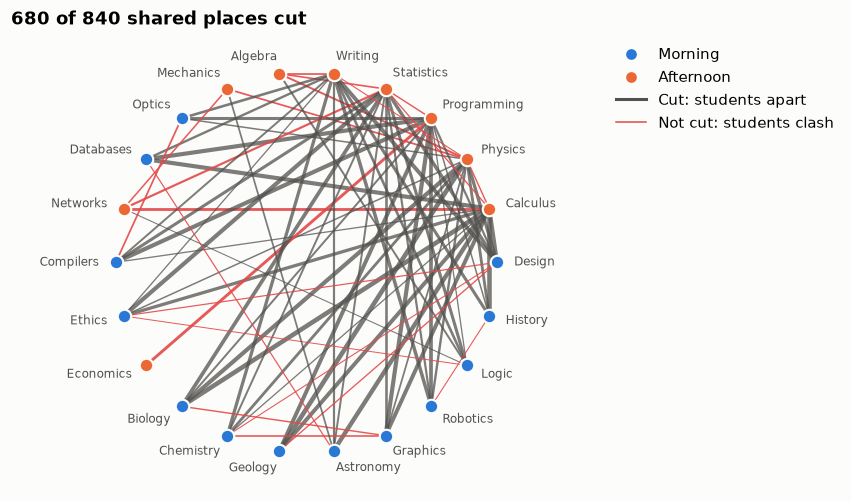

In [5]:
SIDE_COLOR = {0: COLORS[0], 1: COLORS[1]}
CLASH_COLOR = COLORS[7]
cut_legend = [
    Line2D([], [], marker="o", linestyle="", color=SIDE_COLOR[0], label="Morning"),
    Line2D([], [], marker="o", linestyle="", color=SIDE_COLOR[1], label="Afternoon"),
    Line2D([], [], color=INK, linewidth=2, label="Cut: students apart"),
    Line2D([], [], color=CLASH_COLOR, linewidth=1, label="Not cut: students clash"),
]

fig, ax = plt.subplots(figsize=(8.6, 5.4))
for (a, b), students in shared.items():
    is_cut = problem.partition[a] != problem.partition[b]
    ax.plot(*zip(CIRCLE[a], CIRCLE[b]), color=INK if is_cut else CLASH_COLOR, zorder=1,
            linewidth=students / 7 if is_cut else 0.5 + students / 14, alpha=0.75 if is_cut else 0.9)
for exam, (x, y) in CIRCLE.items():
    ax.scatter(x, y, s=78, color=SIDE_COLOR[problem.partition[exam]], edgecolor="#fcfcfb", linewidth=1.4, zorder=2)
draw_labels(ax)
ax.set_title(f"{problem.cut_weight} of {total_students} shared places cut")
ax.legend(handles=cut_legend, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

Recompute the cut and the rules from `partition` and the input, with no solver code.

With 22 vertices a stronger check is possible. There are only about two million splits once a plan
and its mirror count as one, so numpy can score all of them and take the best allowed one. That
proves the answer for this instance. Each added exam doubles the work, which is why the solver
exists.

In [6]:
side = problem.partition
recomputed = sum(students for (a, b), students in shared.items() if side[a] != side[b])
print("cut recomputed       :", recomputed, "matches" if recomputed == problem.cut_weight else "DIFFERS")
print("exams per sitting    :", len(morning), len(afternoon), f"(limit {HALL_LIMIT})")
print("Biology with Chemistry:", side["Biology"] == side["Chemistry"])
print("Optics apart from Mechanics:", side["Optics"] != side["Mechanics"])

# The last exam stays on side 0, which removes the mirror images.
splits = np.arange(2 ** (len(EXAMS) - 1), dtype=np.uint32)
on_side_one = {exam: (splits >> index & 1).astype(bool) for index, exam in enumerate(EXAMS)}
cut_of_split = np.zeros(splits.size, dtype=np.int32)
for (a, b), students in shared.items():
    cut_of_split += students * (on_side_one[a] ^ on_side_one[b])
side_sizes = np.sum([on_side_one[exam] for exam in EXAMS], axis=0, dtype=np.int32)
pair_rules_hold = (on_side_one["Biology"] == on_side_one["Chemistry"]) & (
    on_side_one["Optics"] != on_side_one["Mechanics"]
)


def best_possible(limit):
    allowed = pair_rules_hold & (side_sizes <= limit) & (len(EXAMS) - side_sizes <= limit)
    return int(cut_of_split[allowed].max())


proven = best_possible(HALL_LIMIT)
print(f"splits tried         : {splits.size}")
print(f"best allowed split   : {proven}")
if problem.cut_weight == proven:
    print("the solver's plan is proven optimal for these rules")
else:
    print(f"the solver's plan is {proven - problem.cut_weight} below the optimum")

cut recomputed       : 680 matches
exams per sitting    : 13 9 (limit 13)
Biology with Chemistry: True
Optics apart from Mechanics: True
splits tried         : 2097152
best allowed split   : 680
the solver's plan is proven optimal for these rules


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and the
`constraints` argument takes the list you want. Only listed constraints are scored. `weight` scales
a rule, `hard` moves it between levels, and `exponent` shapes large violations.

The core subjects share students with nearly everything, so the graph pulls them to one side and the
electives to the other. The hall limit holds that back. Leaving `partition_size_bounds` out of the
list shows how far it pulls. The two sittings are drawn as columns: straight lines across are cut,
and arcs on one side are clashes.

`partition_balance` is the soft version of the same idea. It ships with weight 0, which means it is
off, and it charges `weight` points per exam of difference between the sittings.

fixed_partition
same_partition_pairs
different_partition_pairs
partition_size_bounds
partition_balance
maximize_cut_weight


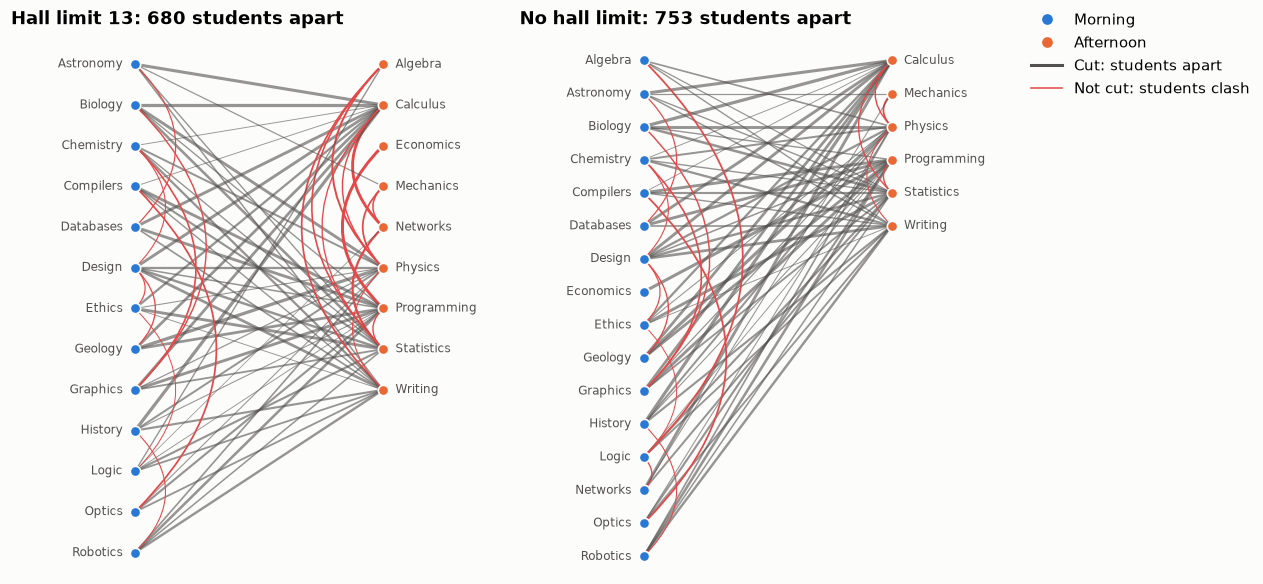

hall limit: score (0, 680.0), sitting sizes [9, 13]
no limit  : score (0, 753.0), sitting sizes [6, 16]


In [7]:
for name in mc.list_constraints():
    print(name)

no_limit = make_problem()
no_limit_score = mc.solve(no_limit, time_limit_seconds=5, config=search_settings(), constraints=[
    rules.fixed_partition,
    rules.same_partition_pairs,
    rules.different_partition_pairs,
    rules.maximize_cut_weight,
])


def draw_sittings(ax, problem):
    columns = {0: [], 1: []}
    for exam in EXAMS:
        columns[problem.partition[exam]].append(exam)
    place = {}
    for number, exams in columns.items():
        for row, exam in enumerate(sorted(exams)):
            place[exam] = (number, 1 - (row + 0.5) / max(len(columns[0]), len(columns[1])))
    for (a, b), students in shared.items():
        if problem.partition[a] != problem.partition[b]:
            ax.plot(*zip(place[a], place[b]), color=INK, linewidth=students / 10, alpha=0.6, zorder=1)
        else:
            bend = 0.5 if problem.partition[a] == 0 else -0.5
            top, bottom = sorted([place[a], place[b]], key=lambda point: -point[1])
            ax.add_patch(FancyArrowPatch(top, bottom, connectionstyle=f"arc3,rad={-bend}", arrowstyle="-",
                                         color=CLASH_COLOR, linewidth=0.5 + students / 14, zorder=1))
    for exam, (x, y) in place.items():
        ax.scatter(x, y, s=46, color=SIDE_COLOR[problem.partition[exam]], edgecolor="#fcfcfb", linewidth=1.1, zorder=2)
        ax.text(x + (-0.05 if x == 0 else 0.05), y, exam, ha="right" if x == 0 else "left", va="center",
                fontsize=8, color=INK)
    ax.set(xlim=(-0.5, 1.5), ylim=(0, 1.02))
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(11.4, 5.2), layout="constrained")
draw_sittings(axes[0], problem)
draw_sittings(axes[1], no_limit)
axes[0].set_title(f"Hall limit {HALL_LIMIT}: {problem.cut_weight} students apart", loc="left")
axes[1].set_title(f"No hall limit: {no_limit.cut_weight} students apart", loc="left")
fig.legend(handles=cut_legend, loc="outside right upper")
plt.show()

print(f"hall limit: score {score}, sitting sizes {sorted(np.bincount(list(problem.partition.values())).tolist())}")
print(f"no limit  : score {no_limit_score}, sitting sizes {sorted(np.bincount(list(no_limit.partition.values())).tolist())}")

## 5. What does each seat limit cost?

A smaller hall forces the two sittings closer to equal. Here the same exams are solved for a range
of limits, against the proven best from the enumeration in section 3, which already covers them.

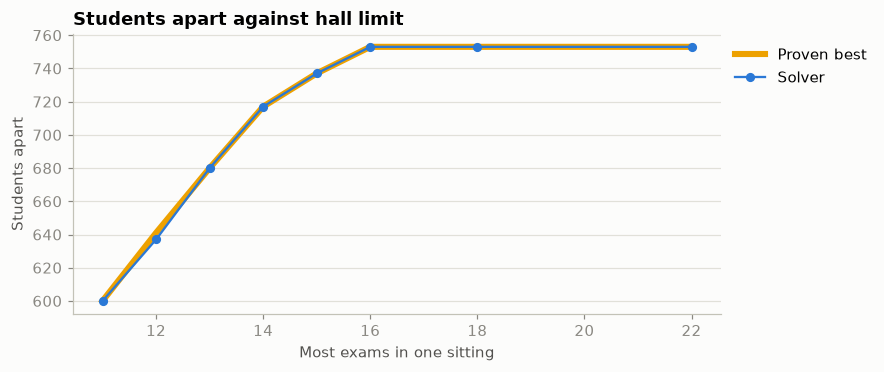

limit 11: solver 600, proven best 600
limit 12: solver 637, proven best 641
limit 13: solver 680, proven best 680
limit 14: solver 717, proven best 717
limit 15: solver 737, proven best 737
limit 16: solver 753, proven best 753  limit does not bind
limit 18: solver 753, proven best 753  limit does not bind
limit 22: solver 753, proven best 753  limit does not bind


In [8]:
limits = [11, 12, 13, 14, 15, 16, 18, 22]
found, proven_best = [], []
for limit in limits:
    candidate = make_problem(limit)
    candidate_score = mc.solve(candidate, time_limit_seconds=5, config=search_settings())
    assert candidate_score[0] == 0, f"no allowed plan found at limit {limit}"
    found.append(candidate.cut_weight)
    proven_best.append(best_possible(limit))

fig, ax = plt.subplots(figsize=(7.6, 3.3))
ax.plot(limits, proven_best, color=COLORS[3], linewidth=4, label="Proven best")
ax.plot(limits, found, color=COLORS[0], linewidth=1.5, marker="o", markersize=5, label="Solver")
ax.set(title="Students apart against hall limit", xlabel="Most exams in one sitting",
       ylabel="Students apart")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

unlimited_size = int(np.max(np.bincount(list(no_limit.partition.values()))))
for limit, value, best in zip(limits, found, proven_best):
    note = "  limit does not bind" if limit >= unlimited_size else ""
    print(f"limit {limit:2d}: solver {value}, proven best {best}{note}")

The curve goes flat where the limit stops binding: once a sitting may hold as many exams as the
unlimited plan from section 4 puts there, a larger hall changes nothing. The loss is steepest at the
tight end, where each exam moved to even out the sittings has to be taken from a well-placed group.

Two usage notes come from this experiment, and both follow from how the search moves.

- **Set both bounds for an exact split.** At limit 11 of 22, `max_partition_size=11` alone already
  forces 11 and 11, but the search only swaps when `min_partition_size` equals it. With only the
  maximum, each single move breaks the limit, and the search is close to stuck where it first lands.
- **Be careful with pair rules next to fixed vertices.** Each step moves one vertex and practically
  never passes through a hard violation. A pair under `different_partition_pairs` or
  `same_partition_pairs` therefore cannot change sides together. Without fixed vertices that does not
  matter, because the rest of the graph can move around the pair. With `fixed_partition`, the pair
  stays the way round it first became valid, and the better way round may be out of reach.

## 6. Restart from an existing plan

`with_initial_solution` starts the search from a solved model, or a dict with a `partition`, instead
of from alternating sides.

**Change `random_seed` between rounds.** A round that finds nothing new leaves the plan as it was,
so with the same seed the next round starts from the same plan with the same random numbers, repeats
the same steps and finds nothing again. The chart starts every run from the alternating sides and
spends 300 steps per round.

same seed 0: [673, 680, 680, 680, 680, 680, 680, 680]
same seed 1: [666, 666, 666, 666, 666, 666, 666, 666]
same seed 2: [650, 657, 657, 657, 657, 657, 657, 657]
same seed 3: [650, 650, 650, 650, 650, 650, 650, 650]
new seeds from 100: [660, 660, 660, 664, 664, 664, 664, 664]
new seeds from 200: [648, 674, 678, 678, 680, 680, 680, 680]
new seeds from 300: [673, 673, 678, 678, 680, 680, 680, 680]
new seeds from 400: [680, 680, 680, 680, 680, 680, 680, 680]


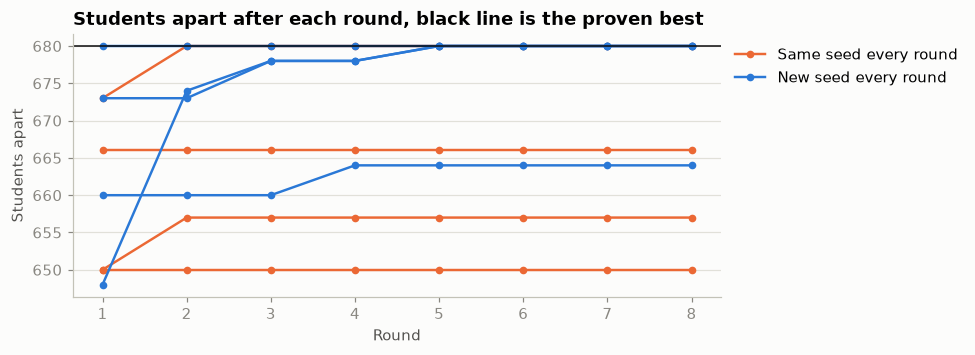

In [9]:
def run_rounds(seeds, steps=300):
    """Students apart after each short round, every round continuing from the previous plan."""
    plan = make_problem()
    mc.solve(plan, config=mc.SolverConfig(max_iterations=0))
    history = []
    for seed in seeds:
        warm = mc.with_initial_solution(make_problem(), plan)
        mc.solve(warm, config=mc.SolverConfig(temperature=30, max_iterations=steps, random_seed=seed))
        plan = warm
        history.append(plan.cut_weight if plan.score_hard == 0 else np.nan)
    return history


ROUNDS = 8
rounds = range(1, ROUNDS + 1)
fig, ax = plt.subplots(figsize=(7.6, 3.1))
for run, seed in enumerate([0, 1, 2, 3]):
    same_seed = run_rounds([seed] * ROUNDS)
    ax.plot(rounds, same_seed, color=COLORS[1], linewidth=1.6, marker="o", markersize=4,
            label="Same seed every round" if run == 0 else None)
    print(f"same seed {seed}:", same_seed)
for run, first_seed in enumerate([100, 200, 300, 400]):
    new_seed = run_rounds(range(first_seed, first_seed + ROUNDS))
    ax.plot(rounds, new_seed, color=COLORS[0], linewidth=1.6, marker="o", markersize=4,
            label="New seed every round" if run == 0 else None)
    print(f"new seeds from {first_seed}:", new_seed)
ax.axhline(proven, color="#0b0b0b", linewidth=1)
ax.set(title="Students apart after each round, black line is the proven best", xlabel="Round",
       ylabel="Students apart")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

A blue line at the black line has nothing left to find. An orange line below it is repeating itself.

### Pinning an exam

`fixed_partition` pins a vertex to a side, and the search never moves it. Suppose the Ethics examiner
can only come for the sitting opposite the one this plan gave. The seed has to agree with the pin, or
`with_initial_solution` raises `ValueError`, so the plan is edited first. A partial plan works too:
vertices left out take their default start.

In [10]:
ethics_side = 1 - problem.partition["Ethics"]
edited = {**problem.partition, "Ethics": ethics_side}

pinned = mc.with_initial_solution(make_problem(fixed_partition={"Ethics": ethics_side}), {"partition": edited})
pinned_score = mc.solve(pinned, time_limit_seconds=5, config=search_settings(seed=7))

moved = [exam for exam in EXAMS if pinned.partition[exam] != problem.partition[exam]]
print(f"before : score {score}, Ethics on side {problem.partition['Ethics']}")
print(f"pinned : score {pinned_score}, Ethics on side {pinned.partition['Ethics']}")
print("changed sitting:", ", ".join(moved))

before : score (0, 680.0), Ethics on side 0
pinned : score (0, 673.0), Ethics on side 1
changed sitting: Networks, Ethics


## Next steps

- `use-cases/max-cut/README.md` covers the solver settings and how to add your own moves and costs in
  Python.
- For assigning many items to many places when the cost of a pair depends on where both land, see
  `quadratic-assignment.ipynb`.